**AI Disclosure:** I used Claude (Anthropic's Claude Code, Sonnet 5.5) to help complete this assignment. It wrote the Part 2 code, the written answers, and the report, and I reviewed the results.

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


**Answer:** The estimated ATE is $-0.01$: 95 of 388 survived with the pump (24.5%) versus 99 of 389 without it (25.4%). A one point difference is basically nothing, and if anything it points the wrong way, so I would not pick the pump.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

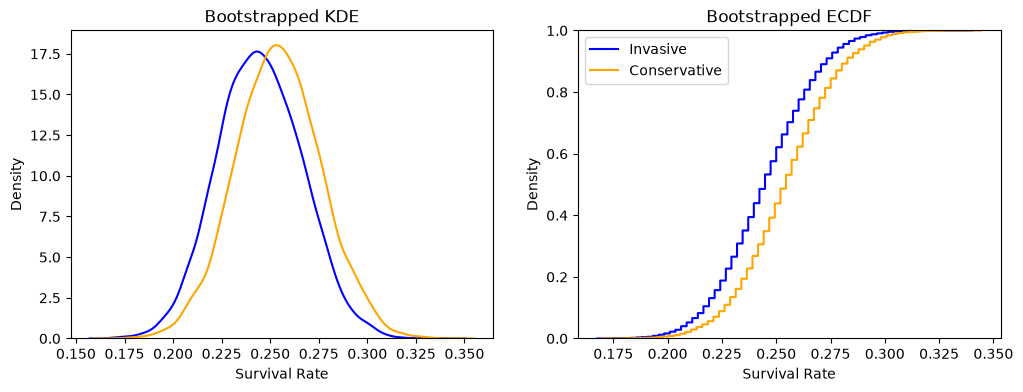

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**Answer:** The two KDEs and ECDFs sit almost on top of each other, both centered near 0.25. The invasive curve is shifted slightly left, but the overlap is huge, so the groups look about the same.

**4.** Make a plot of the KDE and ECDF for the ATE. 

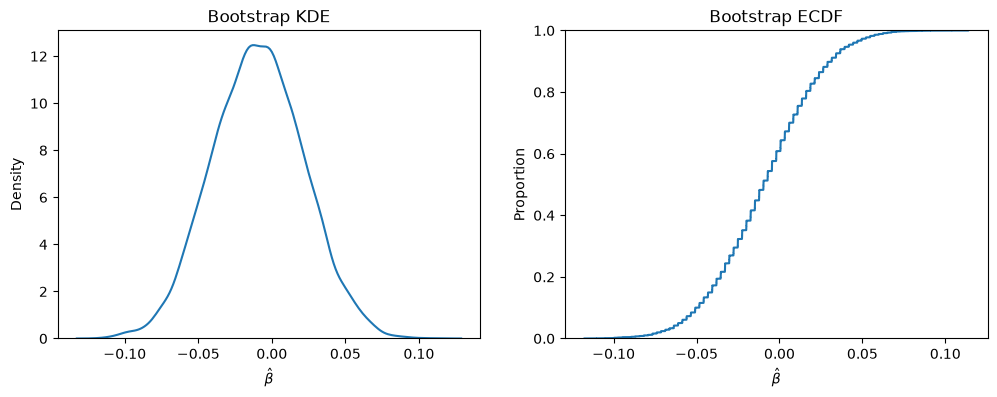

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**Answer:** The ATE distribution is roughly bell shaped and centered near $-0.01$. It spans from about $-0.09$ to $0.07$, so zero sits right in the middle.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06102251  0.04181353]
95% CI: [-0.0688787   0.05210972]
99% CI: [-0.08943104  0.06761323]


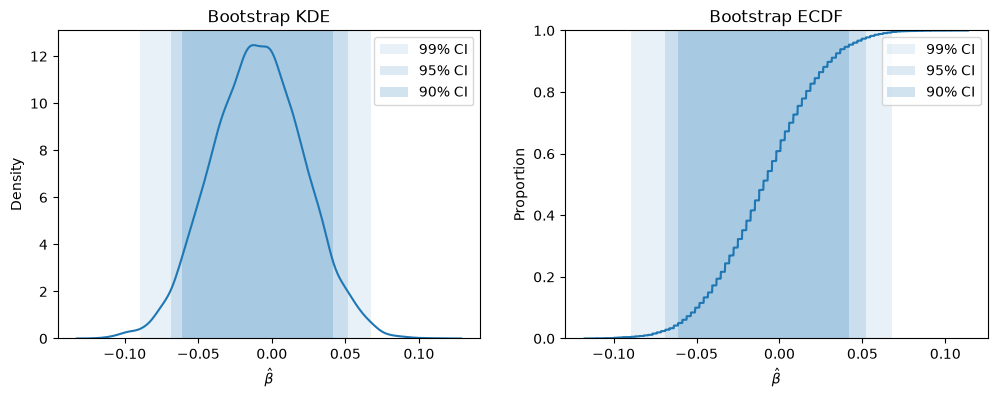

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**Answer:** Zero is inside all three intervals ($-0.061$ to $0.042$ for 90%, $-0.071$ to $0.052$ for 95%, $-0.092$ to $0.070$ for 99%). So we fail to reject the null hypothesis of zero effect at every level. We reject it at none.

**6.** What have we learned about inserting balloons into hearts?

**Answer:** We did not learn that the balloon pumps work. Survival was about the same with and without them, and the intervals are wide enough to include both a modest benefit and a modest harm. That is not proof of no effect, just no evidence of one, so a larger trial would be needed to say more.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## Part 2 Solutions

**1.** Load the data, cross tabulate, and get the average outcomes.

In [8]:
df2 = pd.read_csv('./data/diabetes.csv')
df2['y'] = (df2['outcome'] == 'success').astype(int)

print(pd.crosstab(df2['treatment'], df2['outcome']), chr(10))
print(df2.groupby('treatment')['y'].mean().round(3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: y, dtype: float64


**Answer:** Success counts are 112/232 for metformin, 143/233 for rosiglitazone, and 125/234 for lifestyle. The average success rates are 0.483, 0.614, and 0.534.

**2.** Bootstrap each arm separately 10,000 times.

In [9]:
R = 10_000
arms = ['met', 'rosi', 'lifestyle']
groups = {a: df2.loc[df2['treatment'] == a, :] for a in arms}
boot = {a: [] for a in arms}

for t in range(R):
    for a in arms:
        boot[a].append(groups[a].sample(frac=1.0, replace=True)['y'].mean())

boot = pd.DataFrame(boot)

# Pairwise ATEs
ates = pd.DataFrame({
    'met - rosi': boot['met'] - boot['rosi'],
    'met - lifestyle': boot['met'] - boot['lifestyle'],
    'rosi - lifestyle': boot['rosi'] - boot['lifestyle'],
})

**3.** Plot the densities and the distributions for the three arms.

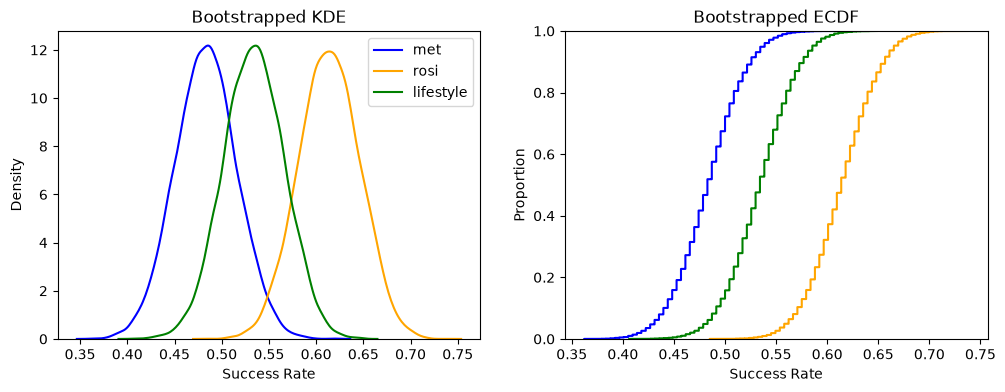

In [10]:
colors = {'met': 'blue', 'rosi': 'orange', 'lifestyle': 'green'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for a in arms:
    sns.kdeplot(boot[a], label=a, color=colors[a], ax=ax[0])
    sns.ecdfplot(boot[a], label=a, color=colors[a], ax=ax[1])

ax[0].set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
ax[1].set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')
ax[0].legend()
plt.show()

**Answer:** Rosiglitazone sits furthest to the right, metformin furthest to the left, and lifestyle in between. All three overlap, especially lifestyle with the other two. Rosi and metformin overlap the least.

**4.** KDE and ECDF plots for the three pairwise treatment effects.

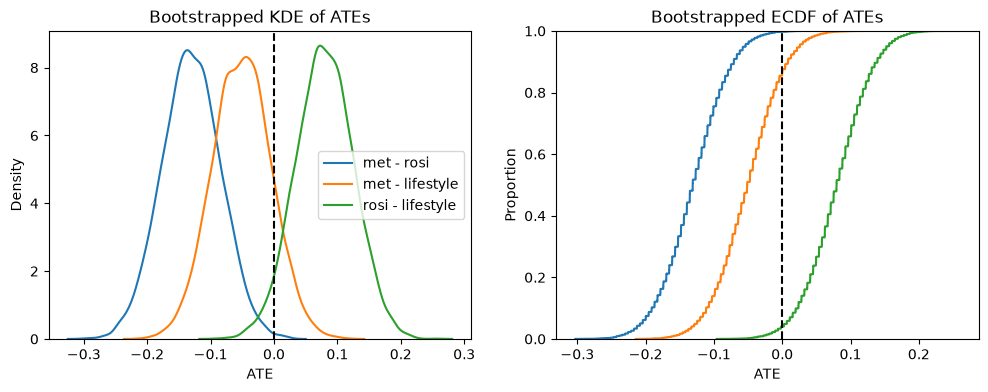

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for c in ates.columns:
    sns.kdeplot(ates[c], label=c, ax=ax[0])
    sns.ecdfplot(ates[c], label=c, ax=ax[1])

ax[0].axvline(0, color='black', linestyle='--')
ax[1].axvline(0, color='black', linestyle='--')
ax[0].set(title='Bootstrapped KDE of ATEs', xlabel='ATE')
ax[1].set(title='Bootstrapped ECDF of ATEs', xlabel='ATE')
ax[0].legend()
plt.show()

**Answer:** Met minus rosi is centered around $-0.13$ and mostly below zero. Rosi minus lifestyle is centered around $0.08$ and mostly above zero. Met minus lifestyle is centered around $-0.05$ and straddles zero.

**5.** Percentile bootstrap confidence intervals for each pairwise ATE.

In [12]:
rows = []
for c in ates.columns:
    for level in [0.90, 0.95, 0.99]:
        lo, hi = np.quantile(ates[c], [(1 - level) / 2, 1 - (1 - level) / 2])
        rows.append({'comparison': c, 'level': level, 'ATE': ates[c].mean().round(3),
                     'lower': lo.round(3), 'upper': hi.round(3), 'zero in CI': lo <= 0 <= hi})

ci_table = pd.DataFrame(rows)
print(ci_table.to_string(index=False))

      comparison  level    ATE  lower  upper  zero in CI
      met - rosi   0.90 -0.131 -0.208 -0.054       False
      met - rosi   0.95 -0.131 -0.221 -0.041       False
      met - rosi   0.99 -0.131 -0.247 -0.011       False
 met - lifestyle   0.90 -0.051 -0.125  0.026        True
 met - lifestyle   0.95 -0.051 -0.141  0.039        True
 met - lifestyle   0.99 -0.051 -0.168  0.069        True
rosi - lifestyle   0.90  0.080  0.007  0.153       False
rosi - lifestyle   0.95  0.080 -0.010  0.169        True
rosi - lifestyle   0.99  0.080 -0.040  0.195        True


**Answer:** Met vs rosi is significant at all three levels (zero is outside every interval). Rosi vs lifestyle is significant only at 90% (95% CI is $-0.010$ to $0.169$). Met vs lifestyle is not significant at any level. Rosiglitazone looks the most effective, and it is clearly better than metformin.

**6. Report**

**Summary.** This report analyzes a randomized trial of three interventions to prevent progression from pre-diabetes to diabetes: metformin, rosiglitazone, and lifestyle changes. About 233 participants were in each arm (699 total). Success rates were compared with a bootstrap that resampled within each arm 10,000 times, which preserves the randomized design.

**Results.** The table below shows the observed outcomes. Rosiglitazone had the highest success rate (61.4%), followed by lifestyle (53.4%) and metformin (48.3%).

| Treatment | Successes | Failures | Success rate |
|---|---|---|---|
| Metformin | 112 | 120 | 0.483 |
| Rosiglitazone | 143 | 90 | 0.614 |
| Lifestyle | 125 | 109 | 0.534 |

Because treatment was randomized, differences in success rates can be read as estimated average treatment effects. The table shows the bootstrap percentile confidence intervals for each pairwise comparison.

| Comparison | ATE | 90% CI | 95% CI | 99% CI |
|---|---|---|---|---|
| Metformin - Rosiglitazone | -0.131 | (-0.208, -0.054) | (-0.221, -0.041) | (-0.247, -0.011) |
| Metformin - Lifestyle | -0.051 | (-0.125, 0.026) | (-0.141, 0.039) | (-0.168, 0.069) |
| Rosiglitazone - Lifestyle | 0.080 | (0.007, 0.153) | (-0.010, 0.169) | (-0.040, 0.195) |

**Interpretation.** The only comparison where zero is excluded at every level is rosiglitazone over metformin, with about 13 more successes per 100 patients. Rosiglitazone over lifestyle is suggestive but fragile: it is significant at 90% but not at 95% or 99%. Metformin and lifestyle cannot be distinguished. The evidence therefore supports rosiglitazone as the most effective of the three, but only metformin is clearly worse, and the benefit over lifestyle is uncertain.

**Limitations and recommendation.** The outcome is a simple success/failure measure, and the data contain no information on side effects, cost, or follow-up length. Those matter for a drug that would be given to millions of people, and a false conclusion that a harmful drug works is the costliest error. We recommend rosiglitazone as the best candidate for further study, not adoption on this evidence alone. Lifestyle changes are a reasonable low-risk option that performed about as well as metformin. This trial does not support metformin over the alternatives. A larger trial including safety outcomes is needed to settle rosiglitazone versus lifestyle.